In [1]:
# CÀI ĐẶT CÁC THƯ VIỆN CẦN THIẾT

!pip install -q pandas numpy matplotlib scipy kagglehub

# Import thư viện xử lý dữ liệu
import pandas as pd
import numpy as np

# Import thư viện trực quan hóa dữ liệu
import matplotlib.pyplot as plt

# Import thư viện kiểm định thống kê
from scipy import stats

# Import thư viện tải dữ liệu từ Kaggle
import kagglehub

# Import thư viện xử lý đường dẫn
import os

# Tắt các cảnh báo không cần thiết
import warnings
warnings.filterwarnings('ignore')

# Hiển thị biểu đồ trực tiếp trong Notebook
%matplotlib inline

print("Các thư viện đã được cài đặt thành công!")


Các thư viện đã được cài đặt thành công!


In [2]:
# GIAI ĐOẠN 1: THU THẬP DỮ LIỆU

# Tải dataset trực tiếp từ Kaggle
path = kagglehub.dataset_download("uciml/red-wine-quality-cortez-et-al-2009")

# Tìm file CSV trong thư mục dataset
file_name = [f for f in os.listdir(path) if f.endswith('.csv')][0]

# Đường dẫn đầy đủ đến file CSV
file_path = os.path.join(path, file_name)

# Đọc dữ liệu
df = pd.read_csv(
    file_path,
    sep=None,
    engine='python'
)

# Tạo bản sao dữ liệu gốc
df_original = df.copy()

print("Tải dữ liệu thành công!")
print("Tên tập dữ liệu:", file_name)

# Hiển thị 5 dòng đầu tiên
print("\n5 dòng dữ liệu đầu tiên:")
display(df.head())

# Kích thước dữ liệu
print("\nKích thước dữ liệu:", df.shape)

Using Colab cache for faster access to the 'red-wine-quality-cortez-et-al-2009' dataset.
Tải dữ liệu thành công!
Tên tập dữ liệu: winequality-red.csv

5 dòng dữ liệu đầu tiên:


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5



Kích thước dữ liệu: (1599, 12)


In [3]:
# KIỂM TRA CẤU TRÚC VÀ CHẤT LƯỢNG DỮ LIỆU

# Thông tin tổng quan
print("THÔNG TIN TỔNG QUAN")
df.info()

# Kiểm tra kiểu dữ liệu
print("\nKIỂU DỮ LIỆU:")
print(df.dtypes)

# Thống kê mô tả
print("\nTHỐNG KÊ MÔ TẢ:")
display(df.describe().T)

# Kiểm tra giá trị thiếu
print("\nGIÁ TRỊ THIẾU:")
missing_data = pd.DataFrame({
    'Missing Values': df.isnull().sum(),
    'Percentage (%)': df.isnull().mean() * 100
})

display(missing_data)

# Kiểm tra dữ liệu trùng lặp
print("\nSỐ LƯỢNG BẢN GHI TRÙNG LẶP:")
print(df.duplicated().sum())

# Kiểm tra số lượng giá trị duy nhất
print("\nSỐ LƯỢNG GIÁ TRỊ DUY NHẤT:")
print(df.nunique())

THÔNG TIN TỔNG QUAN
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1599 entries, 0 to 1598
Data columns (total 12 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         1599 non-null   float64
 1   volatile acidity      1599 non-null   float64
 2   citric acid           1599 non-null   float64
 3   residual sugar        1599 non-null   float64
 4   chlorides             1599 non-null   float64
 5   free sulfur dioxide   1599 non-null   float64
 6   total sulfur dioxide  1599 non-null   float64
 7   density               1599 non-null   float64
 8   pH                    1599 non-null   float64
 9   sulphates             1599 non-null   float64
 10  alcohol               1599 non-null   float64
 11  quality               1599 non-null   int64  
dtypes: float64(11), int64(1)
memory usage: 150.0 KB

KIỂU DỮ LIỆU:
fixed acidity           float64
volatile acidity        float64
citric acid             flo

,count,mean,std,min,25%,50%,75%,max
fixed acidity,1599.0,8.319637,1.741096,4.60000,7.1000,7.90000,9.200000,15.90000
volatile acidity,1599.0,0.527821,0.179060,0.12000,0.3900,0.52000,0.640000,1.58000
citric acid,1599.0,0.270976,0.194801,0.00000,0.0900,0.26000,0.420000,1.00000
residual sugar,1599.0,2.538806,1.409928,0.90000,1.9000,2.20000,2.600000,15.50000
chlorides,1599.0,0.087467,0.047065,0.01200,0.0700,0.07900,0.090000,0.61100
free sulfur dioxide,1599.0,15.874922,10.460157,1.00000,7.0000,14.00000,21.000000,72.00000
total sulfur dioxide,1599.0,46.467792,32.895324,6.00000,22.0000,38.00000,62.000000,289.00000
density,1599.0,0.996747,0.001887,0.99007,0.9956,0.99675,0.997835,1.00369
pH,1599.0,3.311113,0.154386,2.74000,3.2100,3.31000,3.400000,4.01000
sulphates,1599.0,0.658149,0.169507,0.33000,0.5500,0.62000,0.730000,2.00000



GIÁ TRỊ THIẾU:


,Missing Values,Percentage (%)
fixed acidity,0,0.0
volatile acidity,0,0.0
citric acid,0,0.0
residual sugar,0,0.0
chlorides,0,0.0
free sulfur dioxide,0,0.0
total sulfur dioxide,0,0.0
density,0,0.0
pH,0,0.0
sulphates,0,0.0



SỐ LƯỢNG BẢN GHI TRÙNG LẶP:
240

SỐ LƯỢNG GIÁ TRỊ DUY NHẤT:
fixed acidity            96
volatile acidity        143
citric acid              80
residual sugar           91
chlorides               153
free sulfur dioxide      60
total sulfur dioxide    144
density                 436
pH                       89
sulphates                96
alcohol                  65
quality                   6
dtype: int64


In [4]:
# GIAI ĐOẠN 2: TIỀN XỬ LÝ DỮ LIỆU

# Kiểm tra dữ liệu trùng lặp
duplicate_count = df.duplicated().sum()

print("Số bản ghi trùng lặp:", duplicate_count)

# Loại bỏ các bản ghi trùng lặp hoàn toàn
df = df.drop_duplicates()

# Kiểm tra lại sau khi xử lý
print("Kích thước dữ liệu sau khi loại bỏ trùng lặp:", df.shape)

# Kiểm tra giá trị thiếu
print("\nSố lượng giá trị thiếu:")
print(df.isnull().sum().sum())

# Xử lý giá trị thiếu nếu có
# Sử dụng Median vì ít bị ảnh hưởng bởi các giá trị ngoại lệ
for col in df.select_dtypes(include=np.number).columns:
    if df[col].isnull().sum() > 0:
        df[col] = df[col].fillna(df[col].median())

print("\nDữ liệu sau khi xử lý:")
print("Số dòng:", df.shape[0])
print("Số cột:", df.shape[1])
print("Số giá trị thiếu:", df.isnull().sum().sum())

Số bản ghi trùng lặp: 240
Kích thước dữ liệu sau khi loại bỏ trùng lặp: (1359, 12)

Số lượng giá trị thiếu:
0

Dữ liệu sau khi xử lý:
Số dòng: 1359
Số cột: 12
Số giá trị thiếu: 0


,Variable,Q1,Q3,IQR,Lower Bound,Upper Bound,Outliers,Percentage (%)
0,fixed acidity,7.1000,9.20000,2.10000,3.95000,12.35000,41,3.016924
1,volatile acidity,0.3900,0.64000,0.25000,0.01500,1.01500,19,1.398087
2,citric acid,0.0900,0.43000,0.34000,-0.42000,0.94000,1,0.073584
3,residual sugar,1.9000,2.60000,0.70000,0.85000,3.65000,126,9.271523
4,chlorides,0.0700,0.09100,0.02100,0.03850,0.12250,87,6.401766
5,free sulfur dioxide,7.0000,21.00000,14.00000,-14.00000,42.00000,26,1.913171
6,total sulfur dioxide,22.0000,63.00000,41.00000,-39.50000,124.50000,45,3.311258
7,density,0.9956,0.99782,0.00222,0.99227,1.00115,35,2.575423
8,pH,3.2100,3.40000,0.19000,2.92500,3.68500,28,2.060338
9,sulphates,0.5500,0.73000,0.18000,0.28000,1.00000,55,4.047093


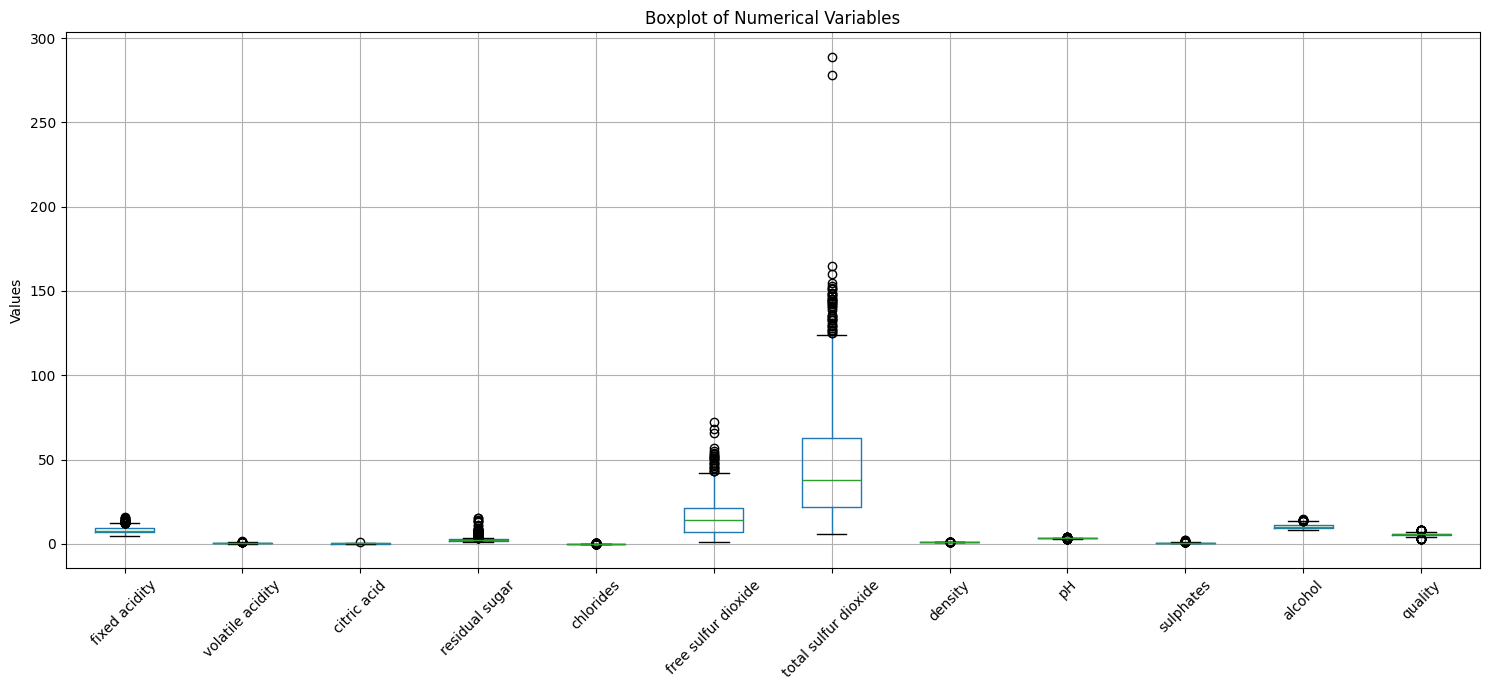

In [5]:
# PHÁT HIỆN GIÁ TRỊ NGOẠI LỆ BẰNG PHƯƠNG PHÁP IQR

numeric_cols = df.select_dtypes(include=np.number).columns

outlier_summary = []

for col in numeric_cols:

    # Tính Q1 và Q3
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)

    # Tính khoảng tứ phân vị
    IQR = Q3 - Q1

    # Xác định giới hạn ngoại lệ
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    # Đếm số lượng ngoại lệ
    outliers = df[
        (df[col] < lower_bound) |
        (df[col] > upper_bound)
    ]

    outlier_summary.append({
        'Variable': col,
        'Q1': Q1,
        'Q3': Q3,
        'IQR': IQR,
        'Lower Bound': lower_bound,
        'Upper Bound': upper_bound,
        'Outliers': len(outliers),
        'Percentage (%)': len(outliers) / len(df) * 100
    })

outlier_df = pd.DataFrame(outlier_summary)

display(outlier_df)

# Vẽ biểu đồ Boxplot
plt.figure(figsize=(15, 7))

df[numeric_cols].boxplot(rot=45)

plt.title("Boxplot of Numerical Variables")
plt.ylabel("Values")
plt.tight_layout()
plt.show()

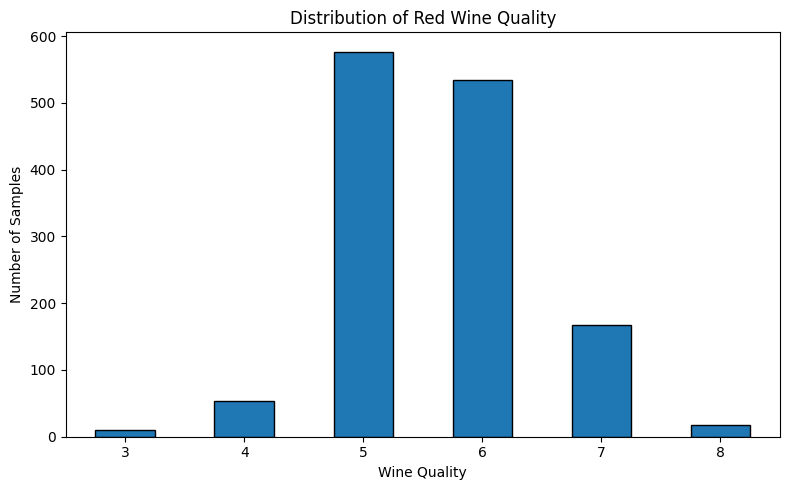

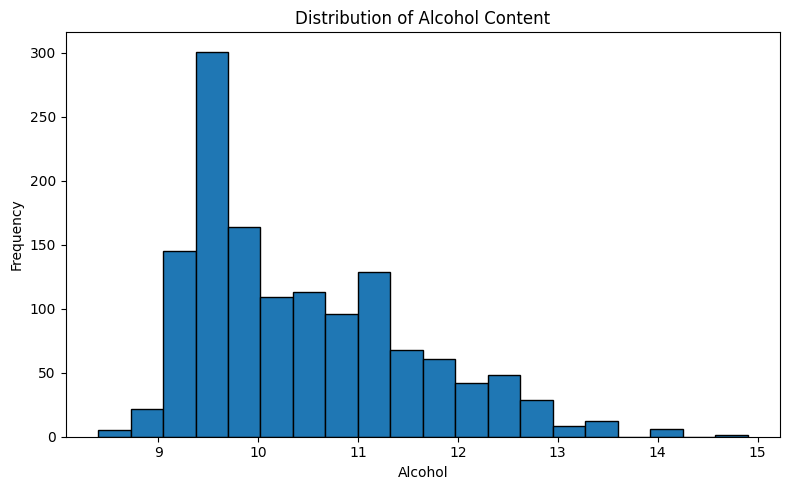

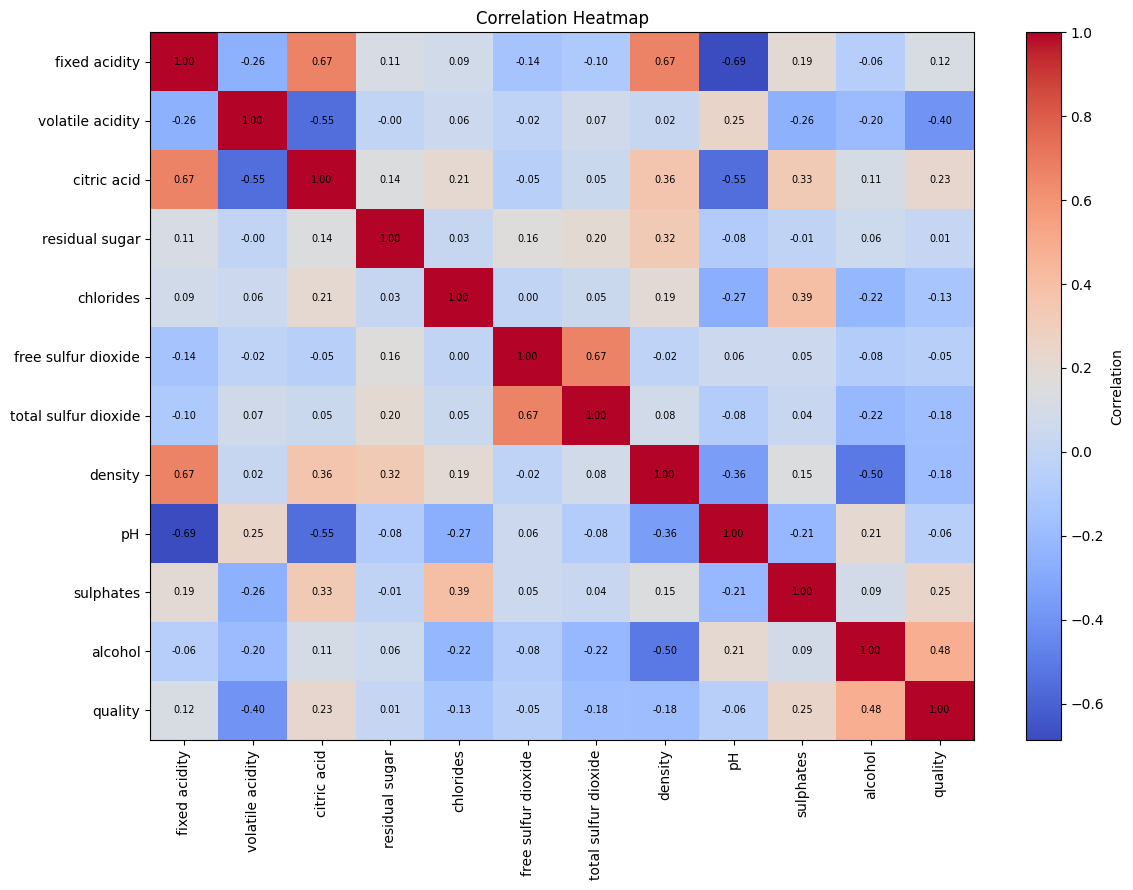

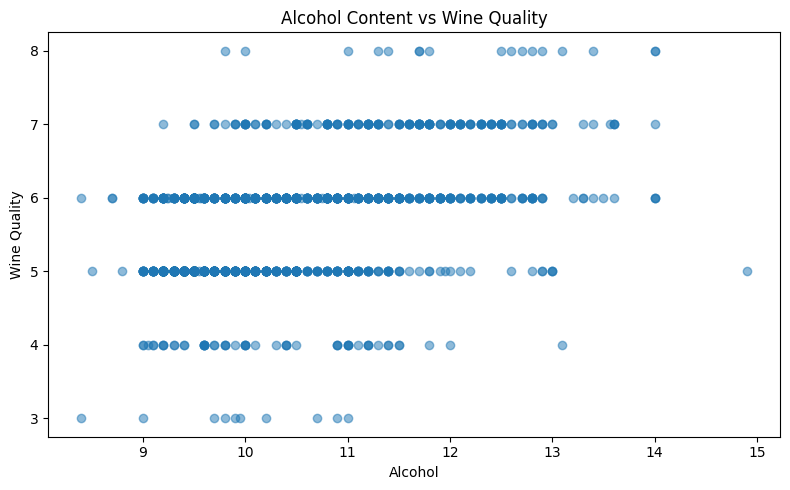

<Figure size 800x500 with 0 Axes>

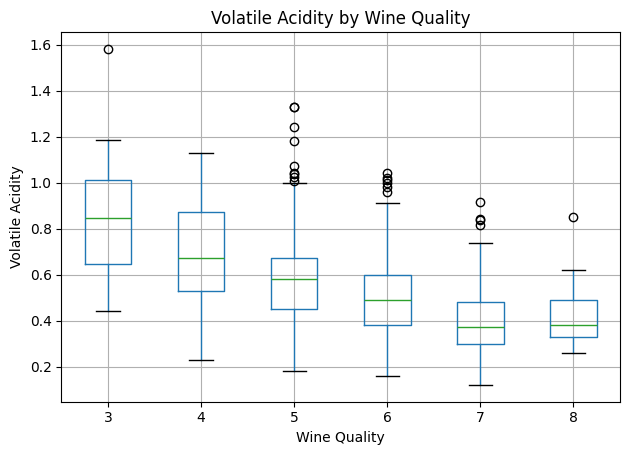

In [6]:
# GIAI ĐOẠN 3: PHÂN TÍCH VÀ TRỰC QUAN HÓA

# 1. Phân phối chất lượng rượu vang
plt.figure(figsize=(8, 5))

df['quality'].value_counts().sort_index().plot(
    kind='bar',
    edgecolor='black'
)

plt.title("Distribution of Red Wine Quality")
plt.xlabel("Wine Quality")
plt.ylabel("Number of Samples")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


# 2. Phân phối nồng độ cồn
plt.figure(figsize=(8, 5))

plt.hist(
    df['alcohol'],
    bins=20,
    edgecolor='black'
)

plt.title("Distribution of Alcohol Content")
plt.xlabel("Alcohol")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()


# 3. Ma trận tương quan giữa các biến
plt.figure(figsize=(12, 9))

correlation = df.corr()

plt.imshow(correlation, cmap='coolwarm', aspect='auto')

plt.colorbar(label='Correlation')

plt.xticks(
    range(len(correlation.columns)),
    correlation.columns,
    rotation=90
)

plt.yticks(
    range(len(correlation.columns)),
    correlation.columns
)

plt.title("Correlation Heatmap")

# Hiển thị hệ số tương quan
for i in range(len(correlation.columns)):
    for j in range(len(correlation.columns)):
        plt.text(
            j, i,
            f'{correlation.iloc[i, j]:.2f}',
            ha='center',
            va='center',
            fontsize=7
        )

plt.tight_layout()
plt.show()


# 4. Mối quan hệ giữa Alcohol và Quality
plt.figure(figsize=(8, 5))

plt.scatter(
    df['alcohol'],
    df['quality'],
    alpha=0.5
)

plt.title("Alcohol Content vs Wine Quality")
plt.xlabel("Alcohol")
plt.ylabel("Wine Quality")
plt.tight_layout()
plt.show()


# 5. Mối quan hệ giữa Volatile Acidity và Quality
plt.figure(figsize=(8, 5))

df.boxplot(
    column='volatile acidity',
    by='quality'
)

plt.title("Volatile Acidity by Wine Quality")
plt.suptitle("")
plt.xlabel("Wine Quality")
plt.ylabel("Volatile Acidity")
plt.tight_layout()
plt.show()

In [7]:
# KIỂM ĐỊNH GIẢ THUYẾT THỐNG KÊ

# H1: Alcohol và Quality có tương quan dương

corr_alcohol, p_alcohol = stats.spearmanr(
    df['alcohol'],
    df['quality']
)

print("KIỂM ĐỊNH H1: ALCOHOL VÀ QUALITY")

print("Spearman correlation:", round(corr_alcohol, 4))
print("P-value:", round(p_alcohol, 5))

if p_alcohol < 0.05 and corr_alcohol > 0:
    print("Kết luận: H1 được ủng hộ.")
else:
    print("Kết luận: H1 chưa được ủng hộ.")


# H2: Volatile Acidity và Quality có tương quan âm

corr_volatile, p_volatile = stats.spearmanr(
    df['volatile acidity'],
    df['quality']
)

print("\nKIỂM ĐỊNH H2: VOLATILE ACIDITY VÀ QUALITY")

print("Spearman correlation:", round(corr_volatile, 4))
print("P-value:", round(p_volatile, 5))

if p_volatile < 0.05 and corr_volatile < 0:
    print("Kết luận: H2 được ủng hộ.")
else:
    print("Kết luận: H2 chưa được ủng hộ.")

KIỂM ĐỊNH H1: ALCOHOL VÀ QUALITY
Spearman correlation: 0.488
P-value: 0.0
Kết luận: H1 được ủng hộ.

KIỂM ĐỊNH H2: VOLATILE ACIDITY VÀ QUALITY
Spearman correlation: -0.3874
P-value: 0.0
Kết luận: H2 được ủng hộ.


SO SÁNH GIÁ TRỊ TRUNG BÌNH:


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
quality_group,,,,,,,,,,,,
High Quality,8.460918,0.472997,0.303296,2.520376,0.082765,15.211405,39.420028,0.996411,3.310473,0.692726,10.887645,6.279555
Low Quality,8.141719,0.592930,0.237547,2.526797,0.094144,16.659375,55.146094,0.997044,3.309016,0.620484,9.920781,4.885937


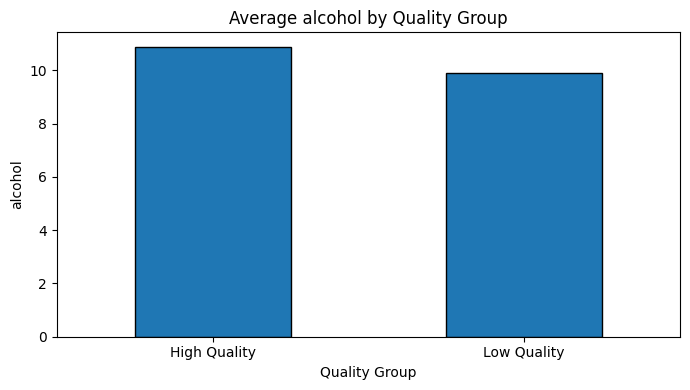

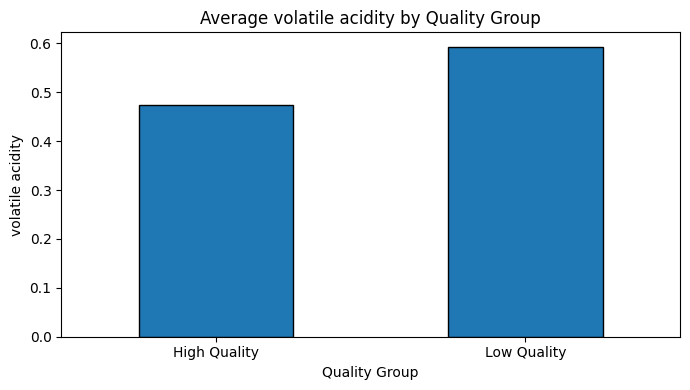

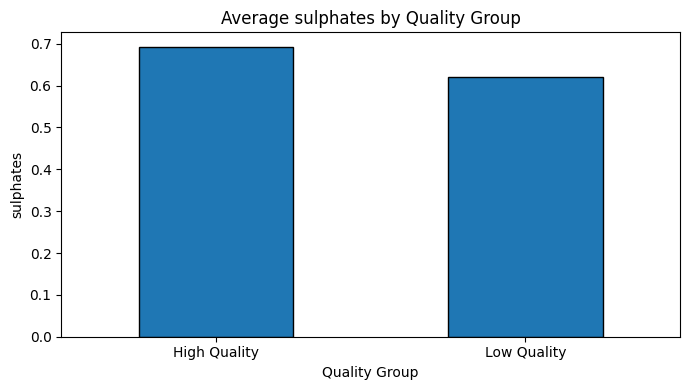

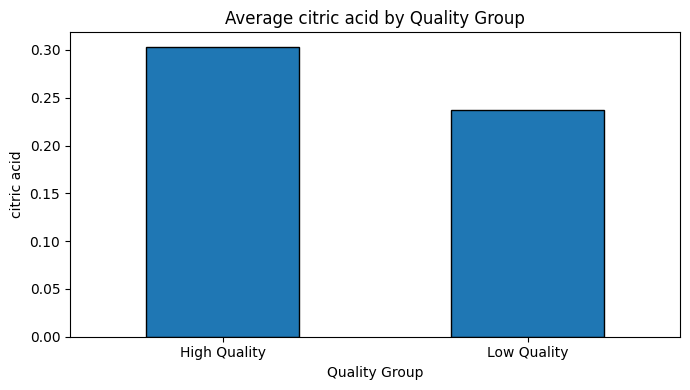


KIỂM ĐỊNH MANN-WHITNEY U

Biến: alcohol
P-value: 0.0
Có sự khác biệt có ý nghĩa thống kê giữa hai nhóm.

Biến: volatile acidity
P-value: 0.0
Có sự khác biệt có ý nghĩa thống kê giữa hai nhóm.

Biến: sulphates
P-value: 0.0
Có sự khác biệt có ý nghĩa thống kê giữa hai nhóm.

Biến: citric acid
P-value: 0.0
Có sự khác biệt có ý nghĩa thống kê giữa hai nhóm.


In [8]:
# SO SÁNH ĐẶC ĐIỂM GIỮA HAI NHÓM CHẤT LƯỢNG

# Tạo biến phân nhóm chất lượng
df['quality_group'] = np.where(
    df['quality'] >= 6,
    'High Quality',
    'Low Quality'
)

# So sánh giá trị trung bình
group_analysis = df.groupby('quality_group')[
    numeric_cols
].mean()

print("SO SÁNH GIÁ TRỊ TRUNG BÌNH:")
display(group_analysis)

# Trực quan hóa các yếu tố tiêu biểu
selected_features = [
    'alcohol',
    'volatile acidity',
    'sulphates',
    'citric acid'
]

for feature in selected_features:

    plt.figure(figsize=(7, 4))

    group_analysis[feature].plot(
        kind='bar',
        edgecolor='black'
    )

    plt.title(f"Average {feature} by Quality Group")
    plt.xlabel("Quality Group")
    plt.ylabel(feature)
    plt.xticks(rotation=0)
    plt.tight_layout()
    plt.show()


# Kiểm định sự khác biệt giữa hai nhóm bằng Mann-Whitney U
print("\nKIỂM ĐỊNH MANN-WHITNEY U")

for feature in selected_features:

    high = df[df['quality_group'] == 'High Quality'][feature]
    low = df[df['quality_group'] == 'Low Quality'][feature]

    statistic, p_value = stats.mannwhitneyu(
        high,
        low,
        alternative='two-sided'
    )

    print(f"\nBiến: {feature}")
    print("P-value:", round(p_value, 5))

    if p_value < 0.05:
        print("Có sự khác biệt có ý nghĩa thống kê giữa hai nhóm.")
    else:
        print("Chưa có bằng chứng về sự khác biệt có ý nghĩa thống kê.")

In [9]:

# TỔNG HỢP KẾT QUẢ PHÂN TÍCH

print("=" * 60)
print("RED WINE QUALITY ANALYSIS - FINAL REPORT")
print("=" * 60)

# 1. Thông tin tổng quan về dữ liệu
print("\n1. DATA OVERVIEW")

print("Number of observations:", len(df))
print("Number of features:", len(df_original.columns) - 1)
print("Missing values:", df.isnull().sum().sum())
print("Duplicate records:", df.duplicated().sum())

# 2. Thống kê chất lượng rượu vang
print("\n2. WINE QUALITY")

print("Average quality:", round(df['quality'].mean(), 2))
print("Median quality:", df['quality'].median())
print("Minimum quality:", df['quality'].min())
print("Maximum quality:", df['quality'].max())

# 3. Phân bố hai nhóm chất lượng
print("\n3. QUALITY GROUP DISTRIBUTION")

quality_counts = df['quality_group'].value_counts()
quality_percent = df['quality_group'].value_counts(
    normalize=True
) * 100

quality_summary = pd.DataFrame({
    'Number of Samples': quality_counts,
    'Percentage (%)': quality_percent.round(2)
})

display(quality_summary)

# 4. Tổng hợp kết quả kiểm định giả thuyết
print("\n4. HYPOTHESIS TESTING")

hypothesis_results = pd.DataFrame({
    'Hypothesis': [
        'H1: Alcohol vs Quality',
        'H2: Volatile Acidity vs Quality'
    ],
    'Spearman Correlation': [
        round(corr_alcohol, 4),
        round(corr_volatile, 4)
    ],
    'P-value': [
        p_alcohol,
        p_volatile
    ],
    'Conclusion': [
        'Supported'
        if p_alcohol < 0.05 and corr_alcohol > 0
        else 'Not Supported',

        'Supported'
        if p_volatile < 0.05 and corr_volatile < 0
        else 'Not Supported'
    ]
})

display(hypothesis_results)

# 5. So sánh các yếu tố giữa hai nhóm chất lượng
print("\n5. COMPARISON BETWEEN QUALITY GROUPS")

selected_features = [
    'alcohol',
    'volatile acidity',
    'sulphates',
    'citric acid'
]

# Tính giá trị trung bình của từng nhóm
group_comparison = df.groupby('quality_group')[
    selected_features
].mean().round(4)

display(group_comparison)

# 6. Kiểm định Mann-Whitney U
print("\n6. MANN-WHITNEY U TEST RESULTS")

mann_whitney_results = []

for feature in selected_features:

    # Lấy dữ liệu của hai nhóm
    high = df[
        df['quality_group'] == 'High Quality'
    ][feature]

    low = df[
        df['quality_group'] == 'Low Quality'
    ][feature]

    # Kiểm định sự khác biệt giữa hai nhóm
    statistic, p_value = stats.mannwhitneyu(
        high,
        low,
        alternative='two-sided'
    )

    # Lưu kết quả kiểm định
    mann_whitney_results.append({
        'Feature': feature,
        'U Statistic': round(statistic, 2),
        'P-value': p_value,
        'Conclusion': (
            'Significant Difference'
            if p_value < 0.05
            else 'Not Significant'
        )
    })

mann_whitney_df = pd.DataFrame(mann_whitney_results)

display(mann_whitney_df)

# 7. Khuyến nghị dựa trên kết quả phân tích
print("\n7. BUSINESS RECOMMENDATIONS")

print("""
- Monitor alcohol concentration during wine production.

- Control volatile acidity to maintain wine quality.

- Regularly monitor chemical characteristics,
  including sulphates and citric acid.

- Use exploratory data analysis and statistical
  hypothesis testing to support quality control.

- Further investigate statistically significant
  factors before making production adjustments.
""")

print("=" * 60)
print("END OF REPORT")
print("=" * 60)


RED WINE QUALITY ANALYSIS - FINAL REPORT

1. DATA OVERVIEW
Number of observations: 1359
Number of features: 11
Missing values: 0
Duplicate records: 0

2. WINE QUALITY
Average quality: 5.62
Median quality: 6.0
Minimum quality: 3
Maximum quality: 8

3. QUALITY GROUP DISTRIBUTION


,Number of Samples,Percentage (%)
quality_group,,
High Quality,719,52.91
Low Quality,640,47.09



4. HYPOTHESIS TESTING


,Hypothesis,Spearman Correlation,P-value,Conclusion
0,H1: Alcohol vs Quality,0.4880,3.238046e-82,Supported
1,H2: Volatile Acidity vs Quality,-0.3874,6.541722e-50,Supported



5. COMPARISON BETWEEN QUALITY GROUPS


,alcohol,volatile acidity,sulphates,citric acid
quality_group,,,,
High Quality,10.8876,0.4730,0.6927,0.3033
Low Quality,9.9208,0.5929,0.6205,0.2375



6. MANN-WHITNEY U TEST RESULTS


,Feature,U Statistic,P-value,Conclusion
0,alcohol,352420.5,1.779910e-64,Significant Difference
1,volatile acidity,140824.0,4.233487e-35,Significant Difference
2,sulphates,319286.0,4.460187e-35,Significant Difference
3,citric acid,274855.0,5.536458e-10,Significant Difference



7. BUSINESS RECOMMENDATIONS

- Monitor alcohol concentration during wine production.

- Control volatile acidity to maintain wine quality.

- Regularly monitor chemical characteristics,
  including sulphates and citric acid.

- Use exploratory data analysis and statistical
  hypothesis testing to support quality control.

- Further investigate statistically significant
  factors before making production adjustments.

END OF REPORT
